## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Diego Josue Lopez Gomez" # @param {"type":"string"}


In [ ]:
carnet = 1000114963 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**
"Una empresa requiere administrar un conjunto de tareas técnicas de soporte e infraestructura priorizadas según su nivel de urgencia, y al mismo tiempo interconectar seis dispositivos físicos distribuidos en un plano bidimensional utilizando la menor longitud total de cable posible.",
 "",
"Para resolver ambos requerimientos en un único entorno ejecutable, el problema se divide en dos componentes algorítmicos:",
        
 "1. **Gestión de tareas por prioridad (Max-Priority Queue):** Se implementa manualmente un 
**Max-Heap** MAX-HEAPIFY, BUILD-MAX-HEAP, EXTRACT-MAX e INSERT sin emplear librerías externas como heapq, permitiendo extraer las tareas más críticas en orden de prioridad e insertar nuevas incidencias de alta urgencia manteniendo la propiedad de montículo.",

 "2. **Optimización de cableado de red (Árbol de Expansión Mínima - MST):** Se modela la red de dispositivos como un grafo completo no dirigido donde los pesos corresponden a la distancia euclidiana entre nodos, y se implementa manualmente el **algoritmo de Kruskal** (junto con una estructura *Disjoint Set / Union-Find* para detección de ciclos) para hallar las 5 conexiones mínimas que interconectan los 6 dispositivos."




## 2) Requerimientos **[2 pts]**
  
RF1: Almacenar las tareas técnicas con su código, descripción y prioridad numérica.",
 
RF3: Implementar EXTRACT-MAX para atender y extraer secuencialmente las dos tareas de mayor prioridad, mostrando el estado del Heap tras cada extracción.\n",
  
RF4:Implementar la inserción de una nueva tarea (T07, prioridad 12) restaurando la propiedad del Max-Heap mediante flotación (*sift-up*) y mostrando el arreglo y árbol resultantes.\n",
 
RF5: Calcular automáticamente las distancias euclidianas entre todos los pares de los 6 dispositivos y graficar su ubicación espacial.\n",
 
RF6: Implementar manualmente el algoritmo de Kruskal (ordenamiento de aristas, verificación de ciclos y selección de $V - 1 = 5$ aristas) para obtener el MST y calcular la longitud total de cable.\n",
 
RF7:Generar una visualización gráfica final con los 6 dispositivos, exclusivamente las aristas del MST, sus pesos individuales y el costo total acumulado.",
        
  **Requerimientos No Funcionales

NF1 (Restricción de librerías): Queda prohibido el uso de heapq para la cola de prioridad y de funciones de librerías de grafos (como networkx o scipy) para calcular el MST.",
 
RNF2 (Autocontención): Todo el código, análisis, gráficas y pruebas deben ejecutarse secuencialmente en un único Notebook de Jupyter parcial_prioridad_mst.ipynb.",
 
RNF3 (Eficiencia algorítmica): La construcción del heap debe operar en $O(n)$, las operaciones de extracción/inserción en $O( \\log n)$ y el algoritmo de Kruskal en $O(E \\log E)$.",
 
RNF4 (Claridad visual): Las representaciones de árboles y planos cartesianos deben etiquetar claramente nodos, prioridades y distancias con dos decimales."




## 3) Historias de usuario **[2 pts]**

HU-01 (Construcción de Cola de Prioridad):*
        "   *Como* coordinador de soporte técnico, *quiero* organizar las tareas pendientes en un Max-Heap según su nivel de urgencia *para* identificar inmediatamente cuál es la incidencia más crítica a atender.  
Criterios de aceptación: Dado el listado inicial de 6 tareas (`T01` a `T06`), al ejecutar `BUILD-MAX-HEAP` la raíz debe ser `T02` (prioridad 10), cumpliendo $A[\\text{Padre}(i)] \\ge A[i]$ para todo nodo $i$, y se debe visualizar tanto el arreglo como el árbol.
        
HU-02 (Atención de Tareas Críticas e Inserción de Emergencias):  
        "   *Como* técnico de turno, *quiero* extraer las tareas de mayor prioridad una por una y poder registrar nuevas fallas críticas en tiempo real *para* mantener actualizada la cola de trabajo sin perder el orden de urgencia.  
Criterios de aceptación: Al ejecutar EXTRACT-MAX dos veces se deben procesar T02 (10) y T04 (8) en ese orden. Al insertar posteriormente T07 (prioridad 12), esta debe ascender a la raíz del Heap.
        
HU-03 (Cálculo de Distancias entre Dispositivos):  
        "   *Como* ingeniero de infraestructura, *quiero* visualizar la ubicación en coordenadas $(X, Y)$ de los 6 dispositivos y calcular las distancias euclidianas entre cada pareja *para* conocer el costo de cableado de cada posible enlace.  
Criterios de aceptación: Se generan las $\\binom{6}{2} = 15$ aristas posibles con sus distancias calculadas mediante $d = \\sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$ y se muestra el plano de dispersión de los nodos.
        
HU-04 (Optimización de Cableado con Kruskal):
        "   *Como* encargado de presupuesto de red, *quiero* obtener el Árbol de Expansión Mínima mediante el algoritmo de Kruskal y visualizar únicamente las conexiones seleccionadas *para* interconectar todos los equipos gastando la menor cantidad de cable posible.  

Criterios de aceptación: El algoritmo selecciona exactamente 5 aristas sin formar ciclos, muestra el listado Nodo1 - Nodo2: peso, reporta la longitud total exacta y dibuja la topología final resultante."

## 4) Diagramas de flujo **[5 pts]**
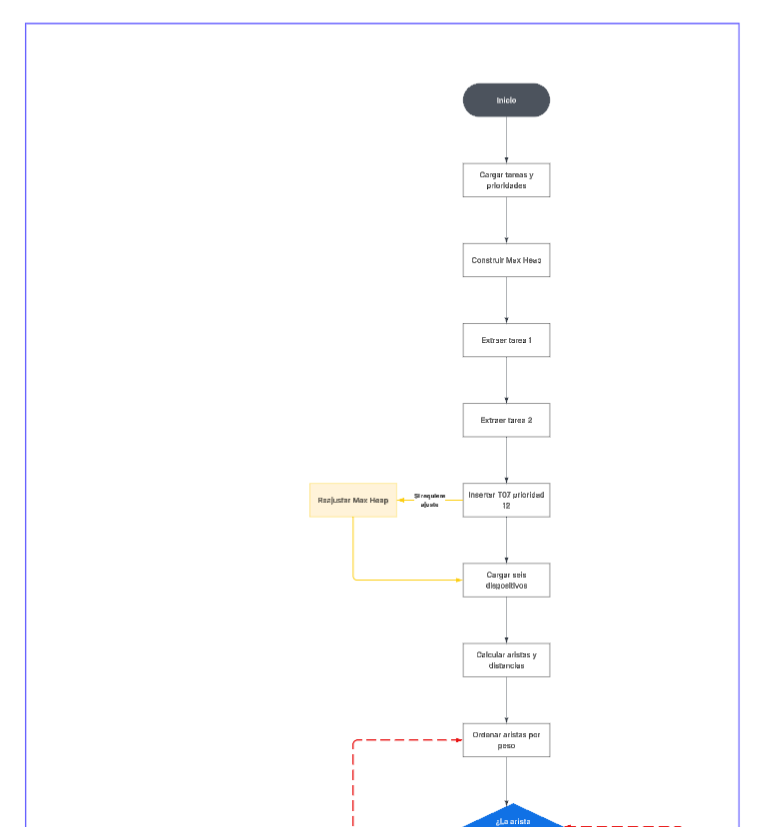

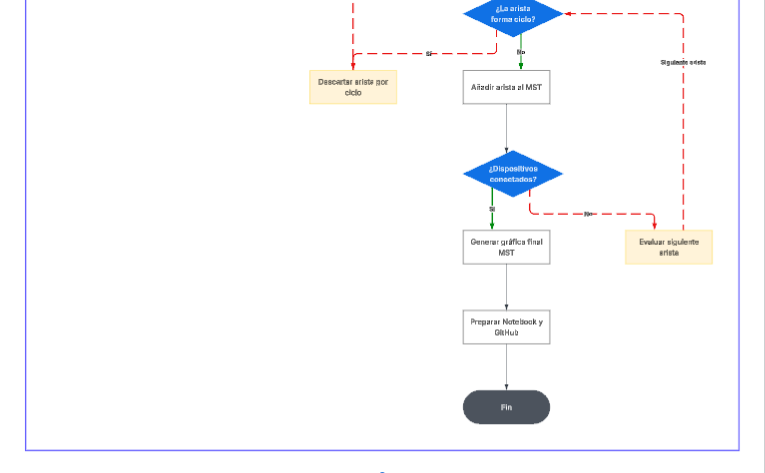

### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica

Justificación
El trabajo combina dos algoritmos fundamentales. Primero se utiliza una cola de prioridad implementada mediante un Max-Heap, porque permite mantener las tareas ordenadas por prioridad sin tener que ordenar nuevamente toda la lista cada vez que se procesa una tarea. La tarea con mayor prioridad siempre queda en la raíz, por lo que EXTRACT-MAX permite obtenerla de forma eficiente. En este caso, las primeras tareas procesadas son T02, con prioridad 10, y T04, con prioridad 8. Luego se inserta T07, con prioridad 12, y se reajusta el heap para conservar su propiedad.

Después se utiliza el algoritmo de Kruskal para conectar los seis dispositivos usando la menor longitud total de cable. Cada dispositivo representa un vértice y cada conexión posible entre dos dispositivos representa una arista cuyo peso es la distancia euclidiana entre sus coordenadas. Kruskal ordena las aristas de menor a mayor y agrega una conexión solamente cuando no forma un ciclo. Como hay seis dispositivos, el árbol de expansión mínima debe terminar con exactamente cinco conexiones.

La solución es adecuada porque el Max-Heap prioriza eficientemente las tareas y Kruskal garantiza un árbol de expansión mínima, es decir, una red conectada con el menor costo total de cable y sin conexiones innecesarias.

Función T[n]
Sea n la cantidad de tareas y v la cantidad de dispositivos. Para el Max-Heap:

BUILD-MAX-HEAP: Θ(n)

EXTRACT-MAX: O(log n) por extracción. Como se realizan dos extracciones, el costo sigue siendo Θ(log n) porque 2 es una constante.

INSERT de T07: O(log n) en el peor caso y O(1) en el mejor caso.

Para Kruskal, si se conectan todos los pares de dispositivos, el número de aristas es e = v(v−1)/2, por lo que e = Θ(v²). Calcular las distancias cuesta Θ(e), ordenar las aristas cuesta Θ(e log e) y seleccionar las aristas mediante conjuntos cuesta aproximadamente O(e α(v)), donde α es la función inversa de Ackermann.

Por tanto, la función total puede expresarse como:

T(n,v) = Θ(n) + Θ(log n) + Θ(log n) + Θ(e) + Θ(e log e)

Como e = Θ(v²), queda:

T(n,v) = Θ(n + log n + v² log v)

Si se considera una sola variable n para representar el tamaño de la entrada, incluyendo tareas y dispositivos, la complejidad dominante es:

T(n) = Θ(n² log n)

La razón es que el grafo completo genera una cantidad cuadrática de conexiones y la ordenación de esas conexiones domina el costo total.

Mejor caso
En el Max-Heap, construir el heap cuesta Θ(n). Una extracción puede resolverse en Θ(1) si, después de mover el último elemento a la raíz, no es necesario realizar intercambios adicionales. La inserción también puede costar Θ(1) si el nuevo elemento no necesita subir por el heap.

En Kruskal, aun en el mejor caso se deben considerar y ordenar las aristas para aplicar el algoritmo de forma general. Por eso, el mejor caso queda dominado por la ordenación:

T_mejor(n) = Θ(n² log n) para un grafo completo.

Peor caso
En el Max-Heap, EXTRACT-MAX puede hacer que el nuevo elemento de la raíz descienda hasta el último nivel, por lo que cuesta Θ(log n). La inserción de T07 también puede hacer que el elemento suba desde una hoja hasta la raíz, con costo Θ(log n).

En Kruskal, se ordenan todas las aristas y pueden descartarse muchas por formar ciclos antes de completar el árbol. Aun así, el costo dominante continúa siendo la ordenación:

T_peor(n) = Θ(n² log n) para un grafo completo.

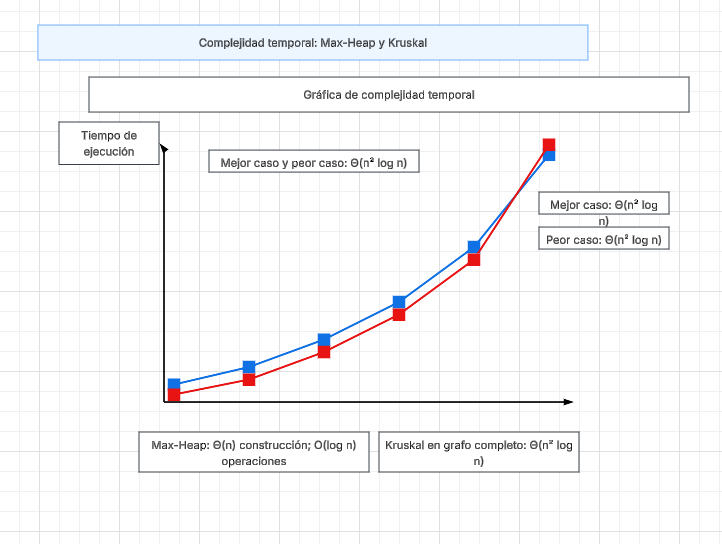

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


## 7) Tests aplicados **[15 pts]**

In [ ]:
# (Opcional) Ejemplo de asserts (ajusta a tu código):
# assert funcion(0) == 0
# assert funcion(1) == 1
# assert funcion(6) == 8
